# Bernstein–Vazirani Algorithm
_A beginner-friendly quantum computing tutorial using Qiskit_

**Original author:** Sanvi Nethikunta · **Team:** Superposition

This revised tutorial uses an ideal local statevector simulator. It does not submit
jobs to quantum hardware. See `docs/correctness-repair.md` for changes to the original.

## The problem and the query model

An oracle implements $f(x)=\alpha\cdot x\pmod 2$ for an unknown $n$-bit string
$\alpha$. The goal is to recover that string. The dot product means multiplying
corresponding bits and adding modulo two (XOR).

A deterministic classical algorithm needs $n$ oracle queries in the worst case:
query each basis string with one bit set. One binary response provides at most one
bit of information about the $2^n$ possible secrets. The ideal quantum algorithm
recovers the string with one coherent oracle application.

This is an **oracle-query comparison**, not a claim that this simulation is faster
than classical computing. Building the known oracle costs gates; statevector
simulation uses resources exponential in the number of qubits. In this tutorial we
know `alpha` to construct and test that oracle; recovery uses the resulting circuit.

We will prepare qubits, inspect phase kickback, decode the input register, and test
both output identity and normalization, including strings that expose bit reversal.

## A classical example: do not assume an unqueried bit

For the following displayed strings, positions are written left to right:

| x | f(x) |
|---|---:|
| 000 | 0 |
| 010 | 1 |
| 100 | 1 |
| 110 | 0 |

These observations imply that the first two displayed secret bits are `11`.
The last bit is **unknown**: both `110` and `111` match every listed query.
The query `001` distinguishes them. If its result is zero, the secret is `110`;
if its result is one, it is `111`. `000` gives no information, and `110` is redundant
once `010` and `100` are known.

In [1]:
def classical_oracle(secret, x):
    assert len(secret) == len(x)
    return sum(int(a) * int(b) for a, b in zip(secret, x)) % 2

observations = {'000': 0, '010': 1, '100': 1, '110': 0}
for candidate in ('110', '111'):
    assert all(classical_oracle(candidate, x) == y for x, y in observations.items())
assert classical_oracle('110', '001') == 0
assert classical_oracle('111', '001') == 1
print('Both 110 and 111 fit; query 001 resolves the missing bit.')

Both 110 and 111 fit; query 001 resolves the missing bit.


## Background: amplitudes, gates, and phase kickback

A qubit has state $|\psi\rangle=a|0\rangle+b|1\rangle$, with complex amplitudes
and $|a|^2+|b|^2=1$. A ket is a column vector; its bra is the conjugate transpose.
Measurement probabilities are squared amplitude magnitudes.

The Pauli-X gate is a single-qubit NOT: $X|0\rangle=|1\rangle$ and
$X|1\rangle=|0\rangle$. A CNOT is a different, two-qubit controlled operation.
Hadamards give $H|0\rangle=|+\rangle$ and $H|1\rangle=|-\rangle$, where
$|\pm\rangle=(|0\rangle\pm|1\rangle)/\sqrt{2}$.

The ancilla's $|-\rangle$ is a **single-qubit state, not a Bell state**. The oracle
acts reversibly as $U_f|x\rangle|y\rangle=|x\rangle|y\oplus f(x)\rangle$.
Since $X|-\rangle=-|-\rangle$, preparing this ancilla produces phase kickback:

$$U_f|x\rangle|-\rangle=(-1)^{\alpha\cdot x}|x\rangle|-\rangle.$$

The relative phases encode the secret. Final Hadamards turn these phases into the
input basis state $|\alpha\rangle$. The ancilla remains separable in this ideal
construction; entanglement with it is not necessary. Entanglement describes joint
states that do not factor into individual states, not faster-than-light signaling.

## Setup and the bit convention

Run this notebook from the cloned repository after installing its requirements.
`bv.py` is the single implementation used for all examples and teaching snapshots.

We write `alpha` as `q_(n-1)...q_0`: the **rightmost bit maps to qubit zero**.
The ancilla is qubit `n`. Circuit diagrams put qubit zero at the top; displayed
bitstrings put it at the right. Thus `alpha='110'` controls the ancilla from input
qubits 2 and 1. Reversing the display of a diagram does not change the computation.

See [IBM's bit-ordering guide](https://quantum.cloud.ibm.com/docs/en/guides/bit-ordering).

In [2]:
%matplotlib inline

import math
from itertools import product

import matplotlib.pyplot as plt
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram

from bv import build_bv, input_probabilities, recover

alpha = '110'
n = len(alpha)

## Step 1: initialize the inputs and ancilla

Start the $n$ input qubits in $|0\rangle$ and flip the ancilla to $|1\rangle$.
The `stage` parameter returns a snapshot of the same tested implementation; it
does not introduce a second circuit builder.

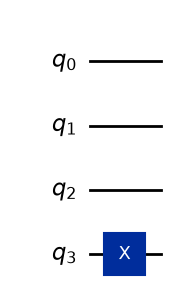

In [3]:
qc = build_bv(alpha, stage='initialize')
display(qc.draw('mpl'))
plt.close('all')

## Step 2: prepare superposition

Apply a Hadamard to each input and to the ancilla. The input register is uniform
over $2^n$ strings, while the ancilla becomes $|-\rangle$.

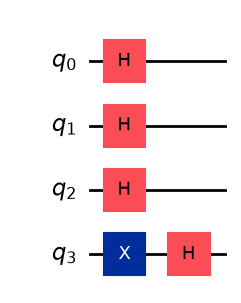

In [4]:
qc = build_bv(alpha, stage='prepare')
display(qc.draw('mpl'))
plt.close('all')

## Step 3: apply the parity oracle

For each secret bit equal to one, apply CNOT from the corresponding input to the
ancilla. The implementation iterates over `reversed(alpha)` to map displayed bits
to qubit labels consistently. On the prepared ancilla, this gives phase kickback.

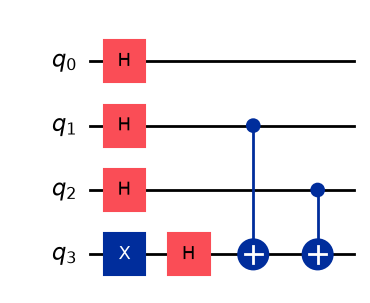

In [5]:
qc = build_bv(alpha, stage='oracle')
display(qc.draw('mpl'))
plt.close('all')

## Step 4: decode the input

Apply Hadamards to the input register again, leaving the ancilla alone. The ideal
state is $|\alpha\rangle|-\rangle$ when registers are described input-first.
The statevector's full basis-string display places the ancilla at the left.

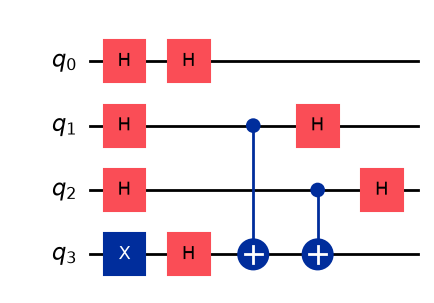

In [6]:
qc = build_bv(alpha)
display(qc.draw('mpl'))
plt.close('all')

## Step 5: measurement wiring

Each input qubit `i` is measured into classical bit `i`. The ancilla is not measured.
The following diagram shows that wiring; it does not submit a hardware job.

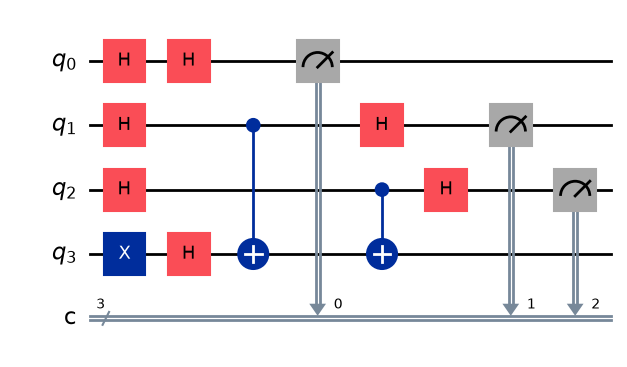

In [7]:
measured_circuit = build_bv(alpha, measure=True)
display(measured_circuit.draw('mpl'))
plt.close('all')

## Step 6: marginal probabilities, not string slicing

`Statevector` computes exact ideal probabilities rather than sampled shot counts.
Request input qubits `0..n-1` so Qiskit **sums over the ancilla**. Truncating full
dictionary keys can overwrite two entries that should be added, losing mass.
Keep the entire distribution for checks; do not discard inconvenient outcomes.

Expected and recovered: 110; total probability: 1.000000000000


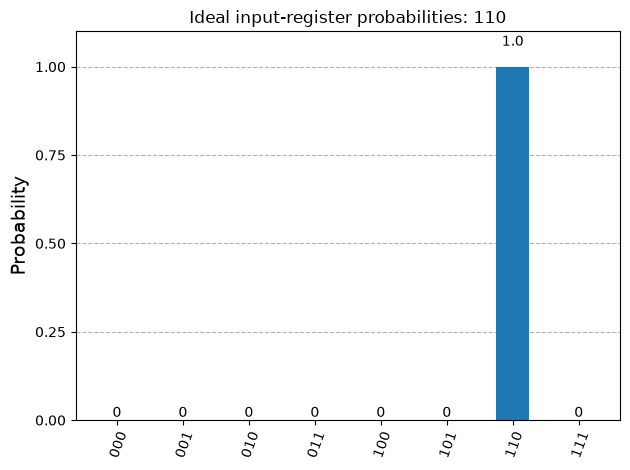

In [8]:
state = Statevector.from_instruction(qc)
probabilities = {str(k): float(v) for k, v in
                 state.probabilities_dict(qargs=list(range(n))).items()}
reference = input_probabilities(alpha)
assert math.isclose(sum(probabilities.values()), 1.0, abs_tol=1e-12)
assert math.isclose(probabilities[alpha], 1.0, abs_tol=1e-12)
assert set(probabilities) == set(reference)
assert all(math.isclose(value, reference[key], abs_tol=1e-12)
           for key, value in probabilities.items())
assert recover(alpha) == alpha
print(f'Expected and recovered: {alpha}; total probability: {sum(probabilities.values()):.12f}')
figure = plot_histogram(probabilities, title=f'Ideal input-register probabilities: {alpha}')
figure.axes[0].set_ylabel('Probability')
plt.show()

The example encodes **110**, so the expected outcome is **110**, with ideal
probability one up to floating-point error. This certainty is a statement about
the noiseless circuit, not about real quantum devices.

## Practice: use fresh state for every secret

Try both palindromic and nonpalindromic strings. Each function call builds a new
circuit and state, so changing `alpha` cannot reuse probabilities from another run.

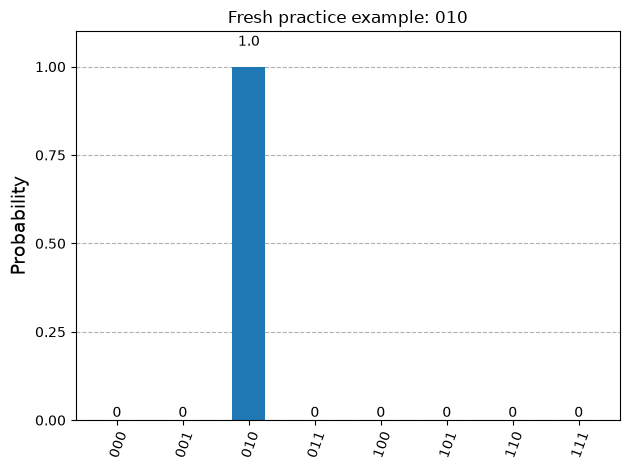

Practice examples passed without shared state.


In [9]:
practice_alpha = '010'
practice_probabilities = input_probabilities(practice_alpha)
assert recover(practice_alpha) == practice_alpha
assert math.isclose(sum(practice_probabilities.values()), 1.0, abs_tol=1e-12)
figure = plot_histogram(practice_probabilities, title=f'Fresh practice example: {practice_alpha}')
figure.axes[0].set_ylabel('Probability')
plt.show()

for secret in ('001', '110', '101', '1011', '010'):
    assert recover(secret) == secret
print('Practice examples passed without shared state.')

## Local validation

A single passing example can conceal reversed bits or a misplaced ancilla. Test
all 126 strings of lengths one through six, checking identity **and** total
probability. The repository's pytest suite additionally checks oracle phases,
measurement wiring, teaching snapshots, and invalid input.

From the repository root run `python -m pytest -q`. To rerun this entire notebook
in a fresh kernel, run `python scripts/check_notebook.py`.

A copyable example is:

```python
from bv import recover
assert recover('001') == '001'
assert recover('110') == '110'
```

In [10]:
checked = 0
for width in range(1, 7):
    for bits in product('01', repeat=width):
        secret = ''.join(bits)
        result = input_probabilities(secret)
        assert math.isclose(sum(result.values()), 1.0, abs_tol=1e-12)
        assert math.isclose(result[secret], 1.0, abs_tol=1e-12)
        assert max(result, key=result.get) == secret
        checked += 1
assert checked == 126
print(f'PASS: all {checked} secrets of lengths 1–6.')

PASS: all 126 secrets of lengths 1–6.


## Hardware execution: an extension, not a reproduced result

This repository currently demonstrates **local ideal statevector simulation only**.
It contains no validated hardware job record, backend calibration snapshot, shot
counts, or measured hardware runtime. Earlier prose claiming a specific deployment
and short runtime was not supported by saved evidence and has been removed.

A future hardware experiment should use the current IBM Runtime interface, select
an available backend, transpile to its connectivity/native gates, and record the
job ID, backend, submission time, shots, calibration context, transpilation settings,
and returned counts. Noise can produce incorrect outcomes. Authenticate through a
supported account flow; do not commit API tokens. Backend availability, queues,
device timing, and account limits must be checked at the time of that experiment.

No hardware code is executed or credentials requested by this notebook.

## Tunable final example

Change `example_alpha`; the input width adjusts automatically. This example uses
exact statevector probabilities, so there is no shots parameter. More qubits
increase local simulation memory exponentially.

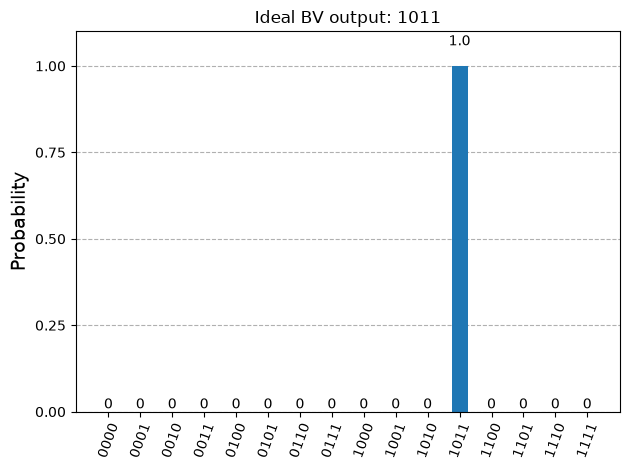

Recovered 1011; distribution preserved and normalized.


In [11]:
example_alpha = '1011'
distribution = input_probabilities(example_alpha)
assert recover(example_alpha) == example_alpha
assert math.isclose(sum(distribution.values()), 1.0, abs_tol=1e-12)
assert math.isclose(distribution[example_alpha], 1.0, abs_tol=1e-12)
figure = plot_histogram(distribution, title=f'Ideal BV output: {example_alpha}')
figure.axes[0].set_ylabel('Probability')
plt.show()
print(f'Recovered {example_alpha}; distribution preserved and normalized.')

## What this establishes

The implementation correctly recovers the tested small secrets in an ideal
simulator under one explicit bit convention. It validates normalization, ancilla
marginalization, independent oracle phase behavior, and repeated example execution.
It does not establish a hardware result, noise robustness, or practical speedup.

The oracle structure is visible in `bv.py`; tests and repair notes explain the
mistakes discovered in the original tutorial and how they were addressed.